In [1]:
print('My Web Scrapping Project')

My Web Scrapping Project


In [2]:
%pip install requests beautifulsoup4 pandas

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [6]:
import requests
import pandas as pd
from bs4 import BeautifulSoup

print('All libraries imported successfully!')

All libraries imported successfully!


In [7]:
import requests
url = 'https://books.toscrape.com/'
response = requests.get(url, timeout = 30)

print('Status Code:', response.status_code)
print('Website URL:', url)

Status Code: 200
Website URL: https://books.toscrape.com/


In [8]:
from bs4 import BeautifulSoup
soup = BeautifulSoup(response.text,'html.parser')
print('Page Title:',soup.title.text)

Page Title: 
    All products | Books to Scrape - Sandbox



In [9]:
# find all books containers on the page
books = soup.select('article.product_pod')

# count the books on the current page
print('Number of books on this page:', len(books))

# Display the HTML structure of the first book
print(books[0].prettify())

Number of books on this page: 20
<article class="product_pod">
 <div class="image_container">
  <a href="catalogue/a-light-in-the-attic_1000/index.html">
   <img alt="A Light in the Attic" class="thumbnail" src="media/cache/2c/da/2cdad67c44b002e7ead0cc35693c0e8b.jpg"/>
  </a>
 </div>
 <p class="star-rating Three">
  <i class="icon-star">
  </i>
  <i class="icon-star">
  </i>
  <i class="icon-star">
  </i>
  <i class="icon-star">
  </i>
  <i class="icon-star">
  </i>
 </p>
 <h3>
  <a href="catalogue/a-light-in-the-attic_1000/index.html" title="A Light in the Attic">
   A Light in the ...
  </a>
 </h3>
 <div class="product_price">
  <p class="price_color">
   Â£51.77
  </p>
  <p class="instock availability">
   <i class="icon-ok">
   </i>
   In stock
  </p>
  <form>
   <button class="btn btn-primary btn-block" data-loading-text="Adding..." type="submit">
    Add to basket
   </button>
  </form>
 </div>
</article>



In [12]:
book_data = []

for book in books:
    title = book.h3.a["title"]
    price = book.select_one(".price_color").text.strip()
    rating = book.select_one(".star-rating")["class"][1]
    availability = book.select_one(".availability").text.strip()
    book_url = book.h3.a["href"]
 
book_data.append({
        "Title": title,
        "Price": price,
        "Rating": rating,
        "Availability": availability,
        "Book_URL": book_url
    })
print("Total books collected:", len(book_data))

print("\nFirst five books:")

for record in book_data[:5]:
    print(record)
    


Total books collected: 1

First five books:
{'Title': "It's Only the Himalayas", 'Price': 'Â£45.17', 'Rating': 'Two', 'Availability': 'In stock', 'Book_URL': 'catalogue/its-only-the-himalayas_981/index.html'}


In [13]:
# Check how many book containers were found
print("Books found:", len(books))

# Check how many records were collected
print("Book records collected:", len(book_data))

Books found: 20
Book records collected: 1


In [14]:
# Reset the list before collecting the records again
book_data = []

# Loop through all 20 books
for book in books:
    title = book.h3.a["title"]
    price = book.select_one(".price_color").text.strip()
    rating = book.select_one(".star-rating")["class"][1]
    availability = book.select_one(".availability").text.strip()
    book_url = book.h3.a["href"]

     record = {
        "Title": title,
        "Price": price,
        "Rating": rating,
        "Availability": availability,
        "Book_URL": book_url
    }

    book_data.append(record)

# Check the results
print("Total book records collected:", len(book_data))

# Display the first five records
for record in book_data[:5]:
    print(record)

    

IndentationError: unexpected indent (25563817.py, line 12)

In [15]:
book_data = []

for book in books:
    title = book.h3.a["title"]
    price = book.select_one(".price_color").text.strip()
    rating = book.select_one(".star-rating")["class"][1]
    availability = book.select_one(".availability").text.strip()
    book_url = book.h3.a["href"]

    book_record = {
    "Title": title,
    "Price": price,
    "Rating": rating,
    "Availability": availability,
    "Book_URL": book_url
    }
    
    book_data.append(book_record)

print("Number of books found:", len(books))
print("Number of book records collected:", len(book_data))
for record in book_data[:5]:
    print(record)

    

Number of books found: 20
Number of book records collected: 20
{'Title': 'A Light in the Attic', 'Price': 'Â£51.77', 'Rating': 'Three', 'Availability': 'In stock', 'Book_URL': 'catalogue/a-light-in-the-attic_1000/index.html'}
{'Title': 'Tipping the Velvet', 'Price': 'Â£53.74', 'Rating': 'One', 'Availability': 'In stock', 'Book_URL': 'catalogue/tipping-the-velvet_999/index.html'}
{'Title': 'Soumission', 'Price': 'Â£50.10', 'Rating': 'One', 'Availability': 'In stock', 'Book_URL': 'catalogue/soumission_998/index.html'}
{'Title': 'Sharp Objects', 'Price': 'Â£47.82', 'Rating': 'Four', 'Availability': 'In stock', 'Book_URL': 'catalogue/sharp-objects_997/index.html'}
{'Title': 'Sapiens: A Brief History of Humankind', 'Price': 'Â£54.23', 'Rating': 'Five', 'Availability': 'In stock', 'Book_URL': 'catalogue/sapiens-a-brief-history-of-humankind_996/index.html'}


In [17]:
# To scrape 1000 books from 50 pages

import requests 
from bs4 import BeautifulSoup 
import pandas as pd 
import time

# Website containing the books 
base_url = "https://books.toscrape.com/catalogue/page-{}.html"

# Store all collected book records 
all_books = []

# Visit the 50 catalogue pages 
for page in range(1, 51):

    url = base_url.format(page) 
    response = requests.get(url, timeout=30)

if response.status_code != 200: 
    print(f"Could not access page {page}") 
    continue

soup = BeautifulSoup(response.text, "html.parser") 
books = soup.select("article.product_pod")
  for book in books: 
      title = book.h3.a["title"] 
      price = book.select_one(".price_color").text.strip() 
      rating = book.select_one(".star-rating")["class"][1] 
      availability = book.select_one(".availability").text.strip() 
      book_url = book.h3.a["href"]

      all_books.append({ 
          "Title": title, 
          "Price": price, 
          "Rating": rating, 
          "Availability": availability, 
          "Book_URL": book_url 
      })

      
print(f"Page {page}: {len(books)} books collected") 

time.sleep(0.2) 

print("\nTotal books collected:", len(all_books))

IndentationError: unexpected indent (592430767.py, line 26)

In [18]:
import requests 
from bs4 import BeautifulSoup 
import pandas as pd 
import time 

base_url = "https://books.toscrape.com/catalogue/page-{}.html" 
all_books = [] 

for page in range(1, 51): 
    url = base_url.format(page) 
    response = requests.get(url, timeout=30) 
    
    if response.status_code != 200: 
        print(f"Could not access page {page}") 
        continue 
        
    soup = BeautifulSoup(response.text, "html.parser") 
    books = soup.select("article.product_pod") 
    
    for book in books: 
        title = book.h3.a["title"] 
        price = book.select_one(".price_color").text.strip() 
        rating = book.select_one(".star-rating")["class"][1] 
        availability = book.select_one(".availability").text.strip() 
        book_url = book.h3.a["href"] 
        
        book_record = { 
            "Title": title, 
            "Price": price, 
            "Rating": rating, 
            "Availability": availability, 
            "Book_URL": book_url 
        } 
        
        all_books.append(book_record) 
    print(f"Page {page}: {len(books)} books collected") 
    time.sleep(0.2) 
print("\nTotal books collected:", len(all_books))

ConnectionError: HTTPSConnectionPool(host='books.toscrape.com', port=443): Max retries exceeded with url: /catalogue/page-1.html (Caused by NameResolutionError("<urllib3.connection.HTTPSConnection object at 0x000001BE221CA5D0>: Failed to resolve 'books.toscrape.com' ([Errno 11001] getaddrinfo failed)"))

In [19]:
import requests 

url = "https://books.toscrape.com/" 

try: response = requests.get(url, timeout=30) 
     print("Connection successful!") 
     print("Status code:", response.status_code) 
except requests.exceptions.RequestException as error: 
     print("Connection failed.") 
     print("Error:", error)

SyntaxError: expected 'except' or 'finally' block (1919385056.py, line 6)

In [20]:
import requests 

url = "https://books.toscrape.com/" 
response = requests.get(url, timeout=30) 

print("Status code:", response.status_code) 
print("Website title:", response.url)

Status code: 200
Website title: https://books.toscrape.com/


In [21]:
import requests 
from bs4 import BeautifulSoup 
import pandas as pd 
import time 

base_url = "https://books.toscrape.com/catalogue/page-{}.html" 
all_books = [] 

for page in range(1, 51): 
    url = base_url.format(page) 
    response = requests.get(url, timeout=30) 
    
    if response.status_code != 200: 
        print("Page", page, "could not be accessed.") 
        continue 
        
        soup = BeautifulSoup(response.text, "html.parser") 
        books = soup.select("article.product_pod") 
        
        for book in books: 
            title = book.h3.a["title"] 
            price = book.select_one(".price_color").text.strip() 
            rating = book.select_one(".star-rating")["class"][1] 
            availability = book.select_one(".availability").text.strip() 
            book_url = book.h3.a["href"] 
            
            book_record = { 
                "Title": title, 
                "Price": price, 
                "Rating": rating, 
                "Availability": availability, 
                "Book_URL": book_url 
            } 
            
            all_books.append(book_record) 
        print("Page", page, "- Books collected:", len(books)) 
        time.sleep(0.2) 
        
    print("Total books collected:", len(all_books))

Total books collected: 0
Total books collected: 0
Total books collected: 0
Total books collected: 0
Total books collected: 0
Total books collected: 0
Total books collected: 0
Total books collected: 0
Total books collected: 0
Total books collected: 0
Total books collected: 0
Total books collected: 0
Total books collected: 0
Total books collected: 0
Total books collected: 0
Total books collected: 0
Total books collected: 0
Total books collected: 0
Total books collected: 0
Total books collected: 0
Total books collected: 0
Total books collected: 0
Total books collected: 0
Total books collected: 0
Total books collected: 0
Total books collected: 0
Total books collected: 0
Total books collected: 0
Total books collected: 0
Total books collected: 0
Total books collected: 0
Total books collected: 0
Total books collected: 0
Total books collected: 0
Total books collected: 0
Total books collected: 0
Total books collected: 0
Total books collected: 0
Total books collected: 0
Total books collected: 0


In [22]:
# test the catalogue page

import requests 
from bs4 import BeautifulSoup 

url = "https://books.toscrape.com/catalogue/page-1.html" 

response = requests.get(url, timeout=30) 

print("Status code:", response.status_code) 
print("Page title:", BeautifulSoup(response.text, "html.parser").title.text) 

soup = BeautifulSoup(response.text, "html.parser") 
books = soup.select("article.product_pod") 

print("Books found:", len(books)) 
print("HTML preview:") 
print(response.text[:300])

Status code: 200
Page title: 
    All products | Books to Scrape - Sandbox

Books found: 20
HTML preview:


<!DOCTYPE html>
<!--[if lt IE 7]>      <html lang="en-us" class="no-js lt-ie9 lt-ie8 lt-ie7"> <![endif]-->
<!--[if IE 7]>         <html lang="en-us" class="no-js lt-ie9 lt-ie8"> <![endif]-->
<!--[if IE 8]>         <html lang="en-us" class="no-js lt-ie9"> <![endif]-->
<!--[if gt IE 8]><!--> <html l


In [23]:
# collect and verify the first 20 books

import requests 
from bs4 import BeautifulSoup 
import pandas as pd 

url = "https://books.toscrape.com/catalogue/page-1.html" 

response = requests.get(url, timeout=30) 
soup = BeautifulSoup(response.text, "html.parser") 

books = soup.select("article.product_pod") 

book_data = [] 

for book in books: 
    title = book.h3.a["title"] 
    price = book.select_one(".price_color").get_text(strip=True) 
    rating = book.select_one(".star-rating")["class"][1] 
    availability = book.select_one(".availability").get_text(strip=True) 
    book_url = book.h3.a["href"]

    book_record = { 
        "Title": title, 
        "Price": price, 
        "Rating": rating, 
        "Availability": availability, 
        "Book_URL": book_url 
    } 
    
    book_data.append(book_record) 
    
print("Books found:", len(books)) 
print("Records collected:", len(book_data)) 

df = pd.DataFrame(book_data)

display(df.head())  

Books found: 20
Records collected: 20


,Title,Price,Rating,Availability,Book_URL
0,A Light in the Attic,Â£51.77,Three,In stock,a-light-in-the-attic_1000/index.html
1,Tipping the Velvet,Â£53.74,One,In stock,tipping-the-velvet_999/index.html
2,Soumission,Â£50.10,One,In stock,soumission_998/index.html
3,Sharp Objects,Â£47.82,Four,In stock,sharp-objects_997/index.html
4,Sapiens: A Brief History of Humankind,Â£54.23,Five,In stock,sapiens-a-brief-history-of-humankind_996/index...


In [24]:
# collect books from 50 catalogues pages

import requests 
from bs4 import BeautifulSoup 
import pandas as pd 
import time 

base_url = "https://books.toscrape.com/catalogue/page-{}.html" 

all_books = [] 

for page in range(1, 51): 
    url = base_url.format(page) 
    
    response = requests.get(url, timeout=30) 
    response.raise_for_status() 
    
    soup = BeautifulSoup(response.text, "html.parser") 
    books = soup.select("article.product_pod") 
    
    for book in books: 
        title = book.h3.a["title"] 
        price = book.select_one(".price_color").get_text(strip=True) 
        rating = book.select_one(".star-rating")["class"][1] 
        availability = book.select_one(".availability").get_text(strip=True) 
        book_url = book.h3.a["href"]
        
        all_books.append({ 
            "Title": title, 
            "Price": price, 
            "Rating": rating, 
            "Availability": availability, 
            "Book_URL": book_url
        }) 
        
    print(f"Page {page}: {len(books)} books collected") 
    
    time.sleep(0.2) 

df = pd.DataFrame(all_books) 

print("\nTotal books collected:", len(df)) 
print("Dataset dimensions:", df.shape) 

display(df.head())

Page 1: 20 books collected
Page 2: 20 books collected
Page 3: 20 books collected
Page 4: 20 books collected
Page 5: 20 books collected
Page 6: 20 books collected
Page 7: 20 books collected
Page 8: 20 books collected
Page 9: 20 books collected
Page 10: 20 books collected
Page 11: 20 books collected
Page 12: 20 books collected
Page 13: 20 books collected
Page 14: 20 books collected
Page 15: 20 books collected
Page 16: 20 books collected
Page 17: 20 books collected
Page 18: 20 books collected
Page 19: 20 books collected
Page 20: 20 books collected
Page 21: 20 books collected
Page 22: 20 books collected
Page 23: 20 books collected
Page 24: 20 books collected
Page 25: 20 books collected
Page 26: 20 books collected
Page 27: 20 books collected
Page 28: 20 books collected
Page 29: 20 books collected
Page 30: 20 books collected
Page 31: 20 books collected
Page 32: 20 books collected
Page 33: 20 books collected
Page 34: 20 books collected
Page 35: 20 books collected
Page 36: 20 books collected
P

,Title,Price,Rating,Availability,Book_URL
0,A Light in the Attic,Â£51.77,Three,In stock,a-light-in-the-attic_1000/index.html
1,Tipping the Velvet,Â£53.74,One,In stock,tipping-the-velvet_999/index.html
2,Soumission,Â£50.10,One,In stock,soumission_998/index.html
3,Sharp Objects,Â£47.82,Four,In stock,sharp-objects_997/index.html
4,Sapiens: A Brief History of Humankind,Â£54.23,Five,In stock,sapiens-a-brief-history-of-humankind_996/index...


In [25]:
# check the total of books scraped

print("Total records in all_books:", len(all_books)) 
print("Dataset dimensions:", df.shape)

Total records in all_books: 1000
Dataset dimensions: (1000, 5)


In [27]:
# Display the dataset's column names and data types 

print("DATASET INFORMATION") 
df.info() 

DATASET INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   Title         1000 non-null   object
 1   Price         1000 non-null   object
 2   Rating        1000 non-null   object
 3   Availability  1000 non-null   object
 4   Book_URL      1000 non-null   object
dtypes: object(5)
memory usage: 39.2+ KB


In [28]:
# Check for missing values print("\nMISSING VALUES") 
print(df.isnull().sum()) 

Title           0
Price           0
Rating          0
Availability    0
Book_URL        0
dtype: int64


In [29]:
# Check for duplicate rows 
print("\nDUPLICATE ROWS") 
print(df.duplicated().sum())


DUPLICATE ROWS
0


In [30]:
# Display the first five records 
print("\nFIRST FIVE RECORDS") 
display(df.head())


FIRST FIVE RECORDS


,Title,Price,Rating,Availability,Book_URL
0,A Light in the Attic,Â£51.77,Three,In stock,a-light-in-the-attic_1000/index.html
1,Tipping the Velvet,Â£53.74,One,In stock,tipping-the-velvet_999/index.html
2,Soumission,Â£50.10,One,In stock,soumission_998/index.html
3,Sharp Objects,Â£47.82,Four,In stock,sharp-objects_997/index.html
4,Sapiens: A Brief History of Humankind,Â£54.23,Five,In stock,sapiens-a-brief-history-of-humankind_996/index...


In [31]:
# Save the dataset as a CSV file 
df.to_csv("books_dataset_cleaned.csv", index=False, encoding="utf-8-sig") 

print("Dataset saved successfully!") 
print("File name: books_dataset_cleaned.csv") 
print("Total records saved:", len(df))

Dataset saved successfully!
File name: books_dataset_cleaned.csv
Total records saved: 1000


In [32]:
#find my dataset location
import os 

print("Your dataset is saved in this folder:") 
print(os.getcwd()) 

print("\nFiles in this folder:") 
print(os.listdir())

Your dataset is saved in this folder:
C:\Users\BRAFAZ

Files in this folder:
['.ai-navigator', '.anaconda', '.conda', '.continuum', '.idlerc', '.ipynb_checkpoints', '.ipython', '.jupyter', '.mamba', '.matplotlib', '.opera', '.python_history', '.virtual_documents', '20CDAAN.ipynb', '20CDAAN_first_class.ipynb', '3D Objects', 'anaconda3', 'anaconda_projects', 'AppData', 'Apple', 'Application Data', 'books_dataset_cleaned.csv', 'Books_web_scrapping_project1.ipynb', 'Book_Web_Scrapping_Project.ipynb', 'Contacts', 'Cookies', 'Da20c.ipynb', 'Documents', 'Downloads', 'edb_languagepack_4.exe', 'edb_languagepack_4.exe-20251218223325', 'edb_npgsql.exe', 'edb_pgagent_pg16.exe', 'edb_pgbouncer.exe', 'edb_pgjdbc.exe', 'edb_psqlodbc.exe', 'edb_psqlodbc.exe-20251215163520', 'edb_psqlodbc.exe-20251215163538', 'edb_psqlodbc.exe-20251215163549', 'edb_psqlodbc.exe-20251218223922', 'Favorites', 'IntelGraphicsProfiles', 'Links', 'Local Settings', 'Microsoft', 'Music', 'My Documents', 'NetHood', 'NTUSER.DAT'

In [33]:
#copy the folder path

import os 
print(os.getcwd())

C:\Users\BRAFAZ


In [34]:
#check for duplicate record

# Check duplicate rows 

print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [35]:
# Check duplicate book titles 

print("Duplicate titles:", df["Title"].duplicated().sum())

Duplicate titles: 1


In [36]:
# Check the number of unique book titles 

print("Unique book titles:", df["Title"].nunique())

Unique book titles: 999


In [37]:
#verify price and rating column

print("Price data type:", df["Price"].dtype) 
print("Rating data type:", df["Rating"].dtype) 


Price data type: object
Rating data type: object


In [38]:
print("Rating data type:", df["Rating"].dtype) 
print("\nRating categories:") 


Rating data type: object

Rating categories:


In [39]:
print("\nPrice summary:") 
print(df["Price"].describe())


Price summary:
count        1000
unique        903
top       Â£44.18
freq            3
Name: Price, dtype: object


In [41]:
# Find book titles that appear more than once
duplicate_titles = df[df["Title"].duplicated(keep=False)]

# Display the repeated titles
display(duplicate_titles[["Title", "Price", "Rating", "Availability"]])

,Title,Price,Rating,Availability
236,The Star-Touched Queen,Â£46.02,Five,In stock
358,The Star-Touched Queen,Â£32.30,Five,In stock


In [42]:
# Display both records for The Star-Touched Queen
df[df["Title"] == "The Star-Touched Queen"]

,Title,Price,Rating,Availability,Book_URL
236,The Star-Touched Queen,Â£46.02,Five,In stock,the-star-touched-queen_764/index.html
358,The Star-Touched Queen,Â£32.30,Five,In stock,the-star-touched-queen_642/index.html


In [43]:
# Display the complete details of both records
duplicate_books = df[df["Title"] == "The Star-Touched Queen"]

display(duplicate_books)

,Title,Price,Rating,Availability,Book_URL
236,The Star-Touched Queen,Â£46.02,Five,In stock,the-star-touched-queen_764/index.html
358,The Star-Touched Queen,Â£32.30,Five,In stock,the-star-touched-queen_642/index.html


In [44]:
# Remove unwanted characters and convert prices to numeric values
df["Price"] = (
    df["Price"]
    .astype(str)
    .str.replace("Â", "", regex=False)
    .str.replace("£", "", regex=False)
    .str.strip()
    .astype(float)
)

# Display the first five cleaned prices
display(df[["Title", "Price"]].head())

# Check the data type of the Price column
print("Price column data type:", df["Price"].dtype)

,Title,Price
0,A Light in the Attic,51.77
1,Tipping the Velvet,53.74
2,Soumission,50.10
3,Sharp Objects,47.82
4,Sapiens: A Brief History of Humankind,54.23


Price column data type: float64


In [45]:
# Check the data types of all columns
print("DATA TYPES")
print(df.dtypes)

print("\nDATASET INFORMATION")
df.info()

DATA TYPES
Title            object
Price           float64
Rating           object
Availability     object
Book_URL         object
dtype: object

DATASET INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Title         1000 non-null   object 
 1   Price         1000 non-null   float64
 2   Rating        1000 non-null   object 
 3   Availability  1000 non-null   object 
 4   Book_URL      1000 non-null   object 
dtypes: float64(1), object(4)
memory usage: 39.2+ KB


In [46]:
# Convert text ratings into numerical values
rating_mapping = {
    "One": 1,
    "Two": 2,
    "Three": 3,
    "Four": 4,
    "Five": 5
}

df["Rating_Number"] = df["Rating"].map(rating_mapping)

# Display the first five records
display(df[["Title", "Rating", "Rating_Number"]].head())

# Check whether any ratings failed to convert
print("Missing numerical ratings:", df["Rating_Number"].isnull().sum())

# Check the new column's data type
print("Rating_Number data type:", df["Rating_Number"].dtype)

,Title,Rating,Rating_Number
0,A Light in the Attic,Three,3
1,Tipping the Velvet,One,1
2,Soumission,One,1
3,Sharp Objects,Four,4
4,Sapiens: A Brief History of Humankind,Five,5


Missing numerical ratings: 0
Rating_Number data type: int64


In [47]:
# 1. Check missing values in every column
print("MISSING VALUES")
print(df.isnull().sum())

# 2. Check duplicate rows
print("\nDUPLICATE ROWS")
print(df.duplicated().sum())

# 3. Check for invalid prices
print("\nPRICE VALIDATION")
print("Prices less than or equal to zero:", (df["Price"] <= 0).sum())
print("Minimum price:", df["Price"].min())
print("Maximum price:", df["Price"].max())

# 4. Check numerical ratings
print("\nRATING VALIDATION")
print("Missing numerical ratings:", df["Rating_Number"].isnull().sum())
print("Minimum rating:", df["Rating_Number"].min())
print("Maximum rating:", df["Rating_Number"].max())

# 5. Check dataset dimensions
print("\nFINAL DATASET DIMENSIONS")
print(df.shape)

MISSING VALUES
Title            0
Price            0
Rating           0
Availability     0
Book_URL         0
Rating_Number    0
dtype: int64

DUPLICATE ROWS
0

PRICE VALIDATION
Prices less than or equal to zero: 0
Minimum price: 10.0
Maximum price: 59.99

RATING VALIDATION
Missing numerical ratings: 0
Minimum rating: 1
Maximum rating: 5

FINAL DATASET DIMENSIONS
(1000, 6)


In [48]:
# Save the cleaned dataset
df.to_csv(
    "books_dataset_cleaned.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Cleaned dataset saved successfully!")
print("Total records:", len(df))
print("Total columns:", len(df.columns))
print("File name: books_dataset_cleaned.csv")

Cleaned dataset saved successfully!
Total records: 1000
Total columns: 6
File name: books_dataset_cleaned.csv


In [49]:
import os

print("Your dataset is saved in this folder:")
print(os.getcwd())

Your dataset is saved in this folder:
C:\Users\BRAFAZ


In [50]:
import os

file_name = "books_dataset_cleaned.csv"

if os.path.exists(file_name):
    print("File found:", os.path.abspath(file_name))
else:
    print("File not found in the current folder.")

File found: C:\Users\BRAFAZ\books_dataset_cleaned.csv


In [51]:
# Calculate descriptive statistics for book prices
print("BOOK PRICE STATISTICS")
display(df["Price"].describe())

# Calculate average and median prices
print("\nAVERAGE BOOK PRICE")
print("£", round(df["Price"].mean(), 2))

print("\nMEDIAN BOOK PRICE")
print("£", round(df["Price"].median(), 2))

# Identify the most expensive book
most_expensive = df.loc[df["Price"].idxmax()]

print("\nMOST EXPENSIVE BOOK")
print("Title:", most_expensive["Title"])
print("Price: £", most_expensive["Price"])

# Identify the cheapest book
cheapest = df.loc[df["Price"].idxmin()]

print("\nCHEAPEST BOOK")
print("Title:", cheapest["Title"])
print("Price: £", cheapest["Price"])

BOOK PRICE STATISTICS


count    1000.00000
mean       35.07035
std        14.44669
min        10.00000
25%        22.10750
50%        35.98000
75%        47.45750
max        59.99000
Name: Price, dtype: float64


AVERAGE BOOK PRICE
£ 35.07

MEDIAN BOOK PRICE
£ 35.98

MOST EXPENSIVE BOOK
Title: The Perfect Play (Play by Play #1)
Price: £ 59.99

CHEAPEST BOOK
Title: An Abundance of Katherines
Price: £ 10.0


In [52]:
# Count books for each numerical rating
rating_counts = df["Rating_Number"].value_counts().sort_index()

print("NUMBER OF BOOKS BY RATING")
display(rating_counts)

# Calculate the percentage of books for each rating
rating_percentages = (
    df["Rating_Number"]
    .value_counts(normalize=True)
    .sort_index()
    .mul(100)
    .round(2)
)

print("PERCENTAGE OF BOOKS BY RATING")
display(rating_percentages)

# Calculate the average rating
print("Average book rating:", round(df["Rating_Number"].mean(), 2))

# Identify the most common rating
print("Most common rating:", df["Rating_Number"].mode().iloc[0])

NUMBER OF BOOKS BY RATING


Rating_Number
1    226
2    196
3    203
4    179
5    196
Name: count, dtype: int64

PERCENTAGE OF BOOKS BY RATING


Rating_Number
1    22.6
2    19.6
3    20.3
4    17.9
5    19.6
Name: proportion, dtype: float64

Average book rating: 2.92
Most common rating: 1


In [53]:
# Count books by availability status
availability_counts = df["Availability"].value_counts()

print("BOOK AVAILABILITY DISTRIBUTION")
display(availability_counts)

# Calculate availability percentages
availability_percentages = (
    df["Availability"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print("AVAILABILITY PERCENTAGES")
display(availability_percentages)

# Display the number of unique availability statuses
print(
    "Number of availability statuses:",
    df["Availability"].nunique()
)

BOOK AVAILABILITY DISTRIBUTION


Availability
In stock    1000
Name: count, dtype: int64

AVAILABILITY PERCENTAGES


Availability
In stock    100.0
Name: proportion, dtype: float64

Number of availability statuses: 1


In [54]:
# Analyze book prices by rating
price_by_rating = df.groupby("Rating_Number")["Price"].agg(
    ["count", "mean", "median", "min", "max"]
)

# Rename columns for clarity
price_by_rating.columns = [
    "Number_of_Books",
    "Average_Price",
    "Median_Price",
    "Minimum_Price",
    "Maximum_Price"
]

# Round price values to two decimal places
price_by_rating[
    ["Average_Price", "Median_Price", "Minimum_Price", "Maximum_Price"]
] = price_by_rating[
    ["Average_Price", "Median_Price", "Minimum_Price", "Maximum_Price"]
].round(2)

print("BOOK PRICE ANALYSIS BY RATING")
display(price_by_rating)

# Identify the rating group with the highest average price
highest_average_rating = price_by_rating["Average_Price"].idxmax()

print(
    "\nRating with the highest average price:",
    highest_average_rating,
    "stars"
)

print(
    "Highest average price: £",
    price_by_rating.loc[highest_average_rating, "Average_Price"]
)

# Identify the rating group with the lowest average price
lowest_average_rating = price_by_rating["Average_Price"].idxmin()

print(
    "\nRating with the lowest average price:",
    lowest_average_rating,
    "stars"
)

print(
    "Lowest average price: £",
    price_by_rating.loc[lowest_average_rating, "Average_Price"]
)

BOOK PRICE ANALYSIS BY RATING


,Number_of_Books,Average_Price,Median_Price,Minimum_Price,Maximum_Price
Rating_Number,,,,,
1,226,34.56,34.77,10.40,59.64
2,196,34.81,36.22,10.02,59.95
3,203,34.69,33.78,10.16,59.99
4,179,36.09,37.80,10.01,59.45
5,196,35.37,36.90,10.00,59.92



Rating with the highest average price: 4 stars
Highest average price: £ 36.09

Rating with the lowest average price: 1 stars
Lowest average price: £ 34.56


In [55]:
# Identify the 10 most expensive books
top_10_expensive = (
    df.nlargest(10, "Price")
    [["Title", "Price", "Rating", "Availability"]]
    .reset_index(drop=True)
)

# Add ranking positions
top_10_expensive.index = top_10_expensive.index + 1
top_10_expensive.index.name = "Rank"

print("TOP 10 MOST EXPENSIVE BOOKS")
display(top_10_expensive)

# Identify the most expensive book's rating
most_expensive_book = df.loc[df["Price"].idxmax()]

print("\nMOST EXPENSIVE BOOK DETAILS")
print("Title:", most_expensive_book["Title"])
print("Price: £", round(most_expensive_book["Price"], 2))
print("Rating:", most_expensive_book["Rating"])

TOP 10 MOST EXPENSIVE BOOKS


,Title,Price,Rating,Availability
Rank,,,,
1,The Perfect Play (Play by Play #1),59.99,Three,In stock
2,Last One Home (New Beginnings #1),59.98,Three,In stock
3,Civilization and Its Discontents,59.95,Two,In stock
4,The Barefoot Contessa Cookbook,59.92,Five,In stock
5,The Diary of a Young Girl,59.90,Three,In stock
6,The Bone Hunters (Lexy Vaughan & Steven Macaul...,59.71,Three,In stock
7,Thomas Jefferson and the Tripoli Pirates: The ...,59.64,One,In stock
8,Boar Island (Anna Pigeon #19),59.48,Three,In stock
9,The Improbability of Love,59.45,One,In stock



MOST EXPENSIVE BOOK DETAILS
Title: The Perfect Play (Play by Play #1)
Price: £ 59.99
Rating: Three


In [56]:
# Identify the 10 cheapest books
bottom_10_cheapest = (
    df.nsmallest(10, "Price")
    [["Title", "Price", "Rating", "Availability"]]
    .reset_index(drop=True)
)

# Add ranking positions
bottom_10_cheapest.index = bottom_10_cheapest.index + 1
bottom_10_cheapest.index.name = "Rank"

print("TOP 10 CHEAPEST BOOKS")
display(bottom_10_cheapest)

# Identify the cheapest book
cheapest_book = df.loc[df["Price"].idxmin()]

print("\nCHEAPEST BOOK DETAILS")
print("Title:", cheapest_book["Title"])
print("Price: £", round(cheapest_book["Price"], 2))
print("Rating:", cheapest_book["Rating"])

TOP 10 CHEAPEST BOOKS


,Title,Price,Rating,Availability
Rank,,,,
1,An Abundance of Katherines,10.00,Five,In stock
2,The Origin of Species,10.01,Four,In stock
3,The Tipping Point: How Little Things Can Make ...,10.02,Two,In stock
4,Patience,10.16,Three,In stock
5,Greek Mythic History,10.23,Five,In stock
6,The Fellowship of the Ring (The Lord of the Ri...,10.27,Two,In stock
7,History of Beauty,10.29,Four,In stock
8,The Lucifer Effect: Understanding How Good Peo...,10.40,One,In stock
9,"NaNo What Now? Finding your editing process, r...",10.41,Four,In stock



CHEAPEST BOOK DETAILS
Title: An Abundance of Katherines
Price: £ 10.0
Rating: Five


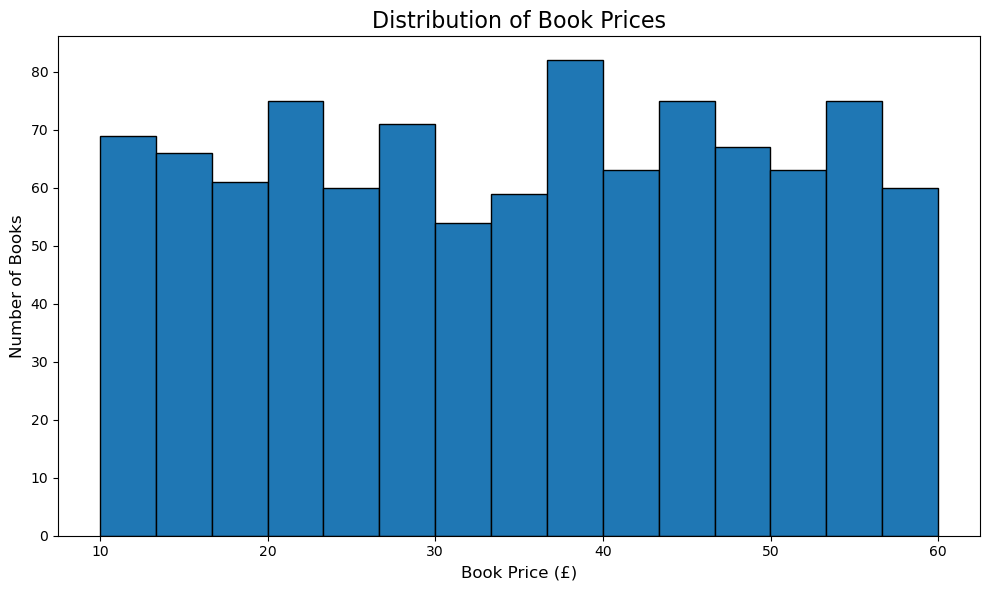

<Figure size 800x500 with 0 Axes>

<Figure size 800x500 with 0 Axes>

In [71]:
#VISUALIZATIONS

import matplotlib.pyplot as plt

# Create a histogram of book prices
plt.figure(figsize=(10, 6))

plt.hist(
    df["Price"],
    bins=15,
    edgecolor="black"
)

plt.title("Distribution of Book Prices", fontsize=16)
plt.xlabel("Book Price (£)", fontsize=12)
plt.ylabel("Number of Books", fontsize=12)

plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))

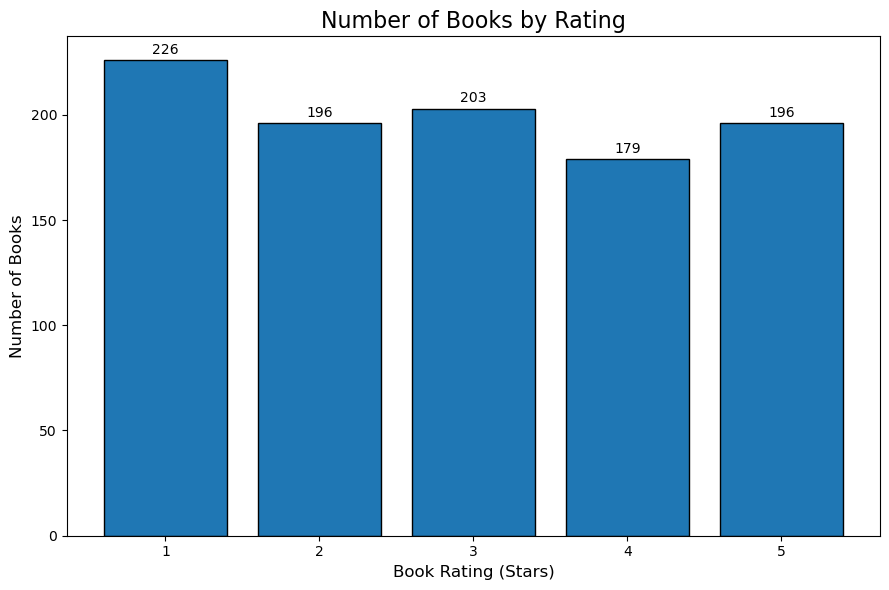

In [75]:
import matplotlib.pyplot as plt

# Count books for each rating
rating_counts = (
    df["Rating_Number"]
    .value_counts()
    .sort_index()
)

# Create a bar chart
plt.figure(figsize=(9, 6))

plt.bar(
    rating_counts.index,
    rating_counts.values,
    edgecolor="black"
)

plt.title("Number of Books by Rating", fontsize=16)
plt.xlabel("Book Rating (Stars)", fontsize=12)
plt.ylabel("Number of Books", fontsize=12)

# Display each rating as a whole number
plt.xticks([1, 2, 3, 4, 5])

# Add count labels above each bar
for rating, count in rating_counts.items():
    plt.text(
        rating,
        count + 3,
        str(count),
        ha="center"
    )

plt.tight_layout()
plt.show()


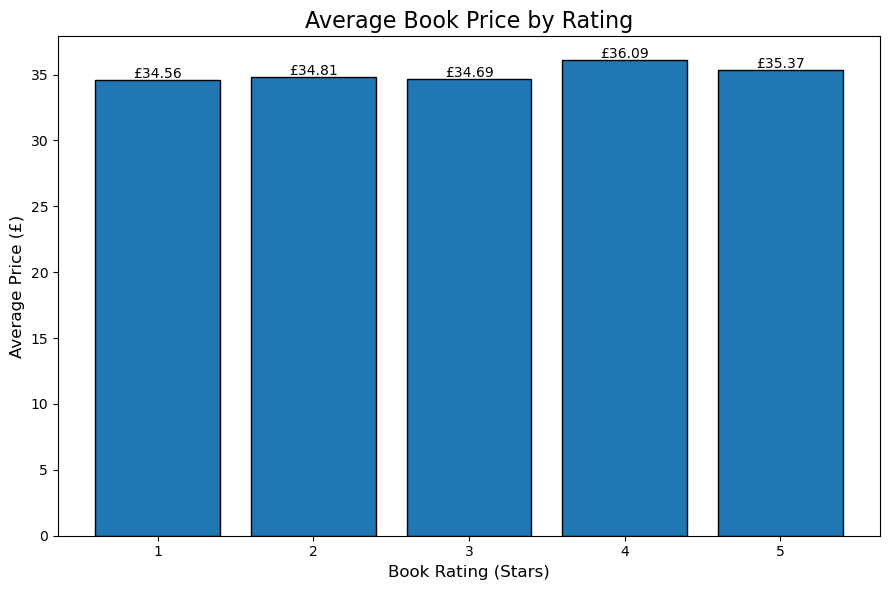

<Figure size 600x400 with 0 Axes>

<Figure size 600x400 with 0 Axes>

In [74]:
import matplotlib.pyplot as plt

# Calculate average price for each rating
average_price_by_rating = (
    df.groupby("Rating_Number")["Price"]
    .mean()
    .sort_index()
)

# Create the bar chart
plt.figure(figsize=(9, 6))

plt.bar(
    average_price_by_rating.index,
    average_price_by_rating.values,
    edgecolor="black"
)

plt.title("Average Book Price by Rating", fontsize=16)
plt.xlabel("Book Rating (Stars)", fontsize=12)
plt.ylabel("Average Price (£)", fontsize=12)

# Display the five rating levels
plt.xticks([1, 2, 3, 4, 5])

# Add average price labels above each bar
for rating, price in average_price_by_rating.items():
    plt.text(
        rating,
        price + 0.15,
        f"£{price:.2f}",
        ha="center"
    )

plt.tight_layout()
plt.show()

plt.figure(figsize=(6, 4))

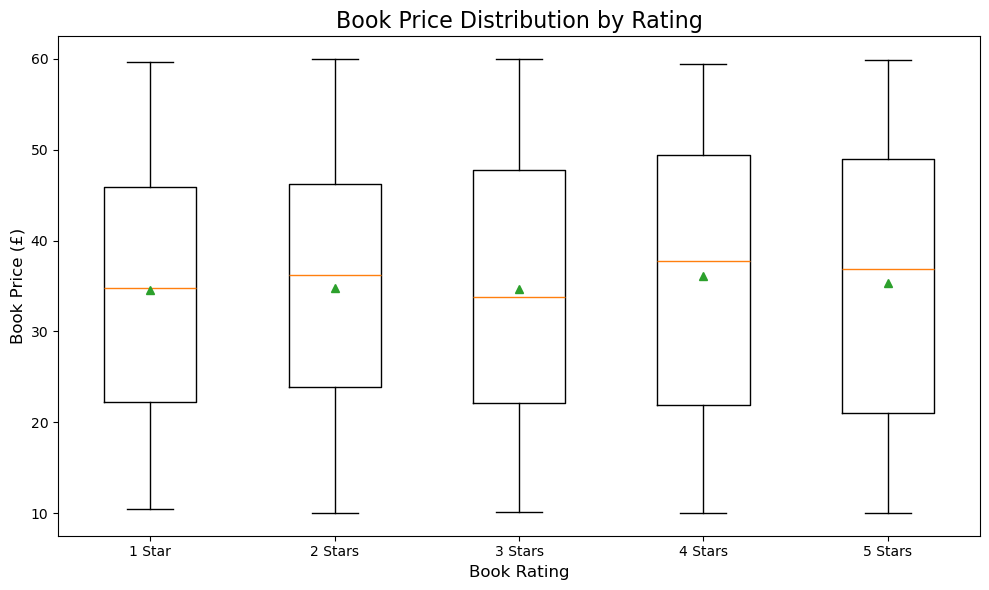

In [60]:
import matplotlib.pyplot as plt

# Group book prices by numerical rating
price_data = [
    df.loc[df["Rating_Number"] == rating, "Price"]
    for rating in sorted(df["Rating_Number"].unique())
]

# Create the box plot
plt.figure(figsize=(10, 6))

plt.boxplot(
    price_data,
    tick_labels=["1 Star", "2 Stars", "3 Stars", "4 Stars", "5 Stars"],
    showmeans=True
)

plt.title("Book Price Distribution by Rating", fontsize=16)
plt.xlabel("Book Rating", fontsize=12)
plt.ylabel("Book Price (£)", fontsize=12)

plt.tight_layout()
plt.show()

import matplotlib.pyplot as plt

# Select the 10 most expensive books
top_10_expensive = df.nlargest(10, "Price").sort_values(
    by="Price", ascending=True
)

# Create a compact horizontal bar chart
plt.figure(figsize=(10, 6))

plt.barh(
    top_10_expensive["Title"],
    top_10_expensive["Price"],
    color="steelblue"
)

# Zoom in on the price axis to show small differences
plt.xlim(59.3, 60.1)

# Display the price at the end of each bar
for index, price in enumerate(top_10_expensive["Price"]):
    plt.text(
        price + 0.005,
        index,
        f"£{price:.2f}",
        va="center",
        fontsize=9
    )

plt.title("Top 10 Most Expensive Books", fontsize=14)
plt.xlabel("Book Price (£)", fontsize=11)
plt.ylabel("Book Title", fontsize=11)

plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))

In [62]:
plt.figure(figsize=(12, 7))

<Figure size 1200x700 with 0 Axes>

<Figure size 1200x700 with 0 Axes>

In [63]:
plt.figure(figsize=(8, 5))

<Figure size 800x500 with 0 Axes>

<Figure size 800x500 with 0 Axes>

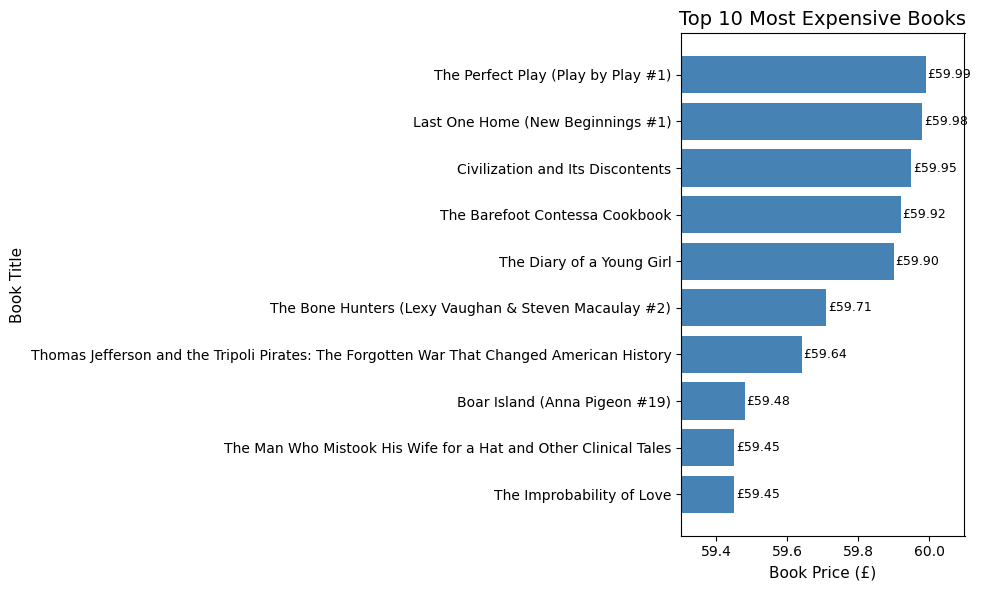

In [65]:
import matplotlib.pyplot as plt

# Select the 10 most expensive books
top_10_expensive = df.nlargest(10, "Price").sort_values(
    by="Price", ascending=True
)

# Create a compact horizontal bar chart
plt.figure(figsize=(10, 6))

plt.barh(
    top_10_expensive["Title"],
    top_10_expensive["Price"],
    color="steelblue"
)

# Zoom in on the price axis to show small differences
plt.xlim(59.3, 60.1)

# Display the price at the end of each bar
for index, price in enumerate(top_10_expensive["Price"]):
    plt.text(
        price + 0.005,
        index,
        f"£{price:.2f}",
        va="center",
        fontsize=9
    )

plt.title("Top 10 Most Expensive Books", fontsize=14)
plt.xlabel("Book Price (£)", fontsize=11)
plt.ylabel("Book Title", fontsize=11)

plt.tight_layout()
plt.show()

C:\Users\BRAFAZ\AppData\Local\Temp\ipykernel_18760\3893033427.py:35: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


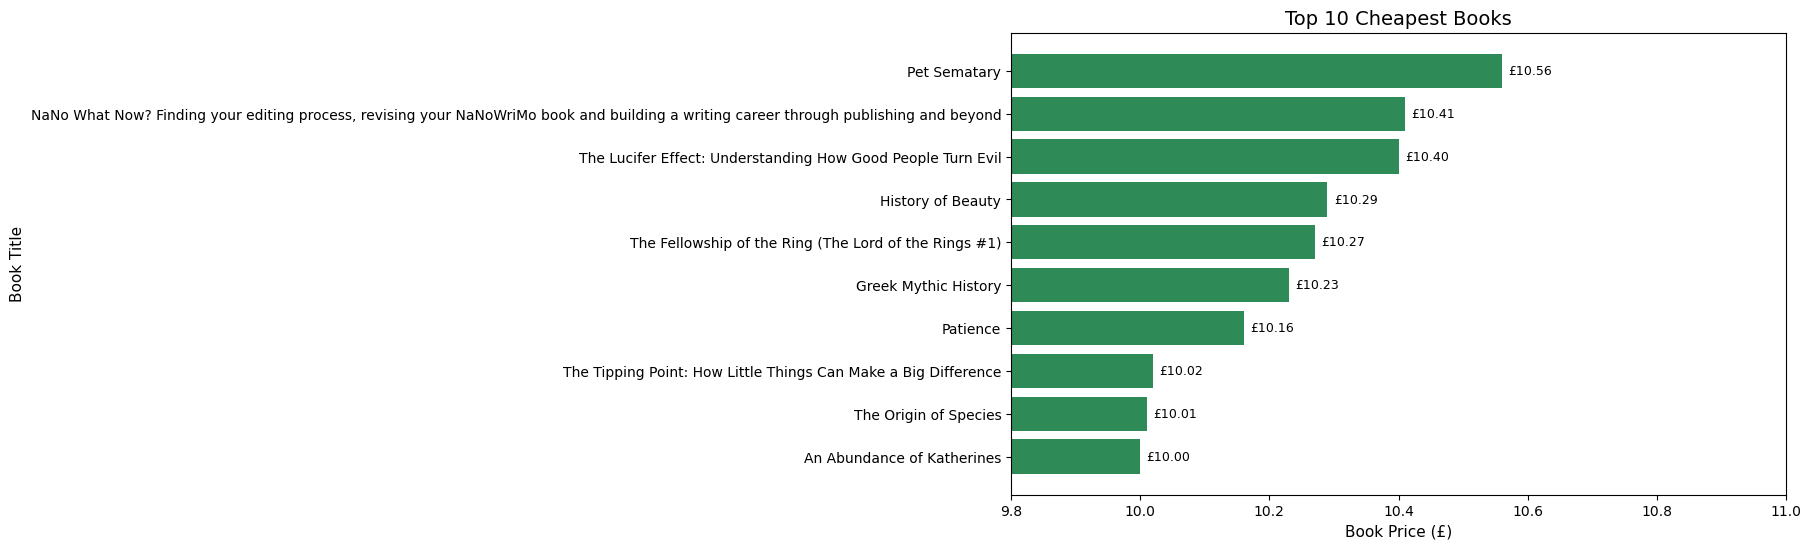

In [76]:
import matplotlib.pyplot as plt

# Select the 10 cheapest books
top_10_cheapest = df.nsmallest(10, "Price").sort_values(
    by="Price", ascending=True
)

# Create a horizontal bar chart
plt.figure(figsize=(10, 6))

plt.barh(
    top_10_cheapest["Title"],
    top_10_cheapest["Price"],
    color="seagreen"
)

# Zoom in on the price axis to make differences visible
plt.xlim(9.8, 11.0)

# Add price labels to the bars
for index, price in enumerate(top_10_cheapest["Price"]):
    plt.text(
        price + 0.01,
        index,
        f"£{price:.2f}",
        va="center",
        fontsize=9
    )

# Add chart titles and labels
plt.title("Top 10 Cheapest Books", fontsize=14)
plt.xlabel("Book Price (£)", fontsize=11)
plt.ylabel("Book Title", fontsize=11)

plt.tight_layout()
plt.show()

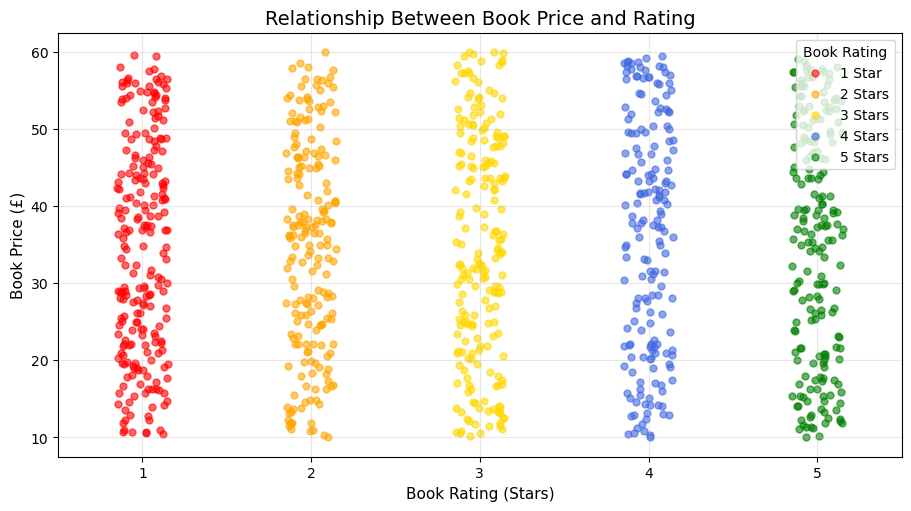

In [79]:
import matplotlib.pyplot as plt
import numpy as np

# Set a random seed so the chart is reproducible
np.random.seed(42)

# Add slight horizontal jitter to separate overlapping points
rating_jitter = df["Rating_Number"] + np.random.uniform(
    -0.15, 0.15, size=len(df)
)

# Create the figure
fig, ax = plt.subplots(figsize=(9, 5), constrained_layout=True)

# Assign a different colour to each rating
rating_colors = {
    1: "red",
    2: "orange",
    3: "gold",
    4: "royalblue",
    5: "green"
}

# Plot each rating category separately
for rating in sorted(df["Rating_Number"].unique()):
    mask = df["Rating_Number"] == rating

    ax.scatter(
        rating_jitter[mask],
        df.loc[mask, "Price"],
        color=rating_colors[rating],
        label=f"{rating} Star{'s' if rating > 1 else ''}",
        alpha=0.6,
        s=25
    )

# Add title and axis labels
ax.set_title("Relationship Between Book Price and Rating", fontsize=14)
ax.set_xlabel("Book Rating (Stars)", fontsize=11)
ax.set_ylabel("Book Price (£)", fontsize=11)

# Format the rating axis
ax.set_xticks([1, 2, 3, 4, 5])
ax.set_xlim(0.5, 5.5)

# Add grid and legend
ax.grid(True, alpha=0.3)
ax.legend(title="Book Rating", loc="upper right")

plt.show()

Key Findings and Insights
1. Dataset Overview

The project collected 1,000 book records from Books to Scrape using Python, Requests, and BeautifulSoup. The dataset contains book titles, prices, star ratings, availability status, and book URLs. Data cleaning and validation were performed using Pandas.

2. Book Price Analysis

The average book price was approximately £35.07, while the median price was £35.98. Prices ranged from £10.00 to £59.99, showing a broad spread across the collected catalogue.

3. Rating Distribution

The dataset contains books rated from one to five stars. One-star books represented the largest rating group, with 226 books (22.6%). Three-star books accounted for 203 records (20.3%), while five-star books accounted for 196 records (19.6%).

4. Price and Rating Comparison

Average prices varied only moderately across the five rating categories. Four-star books had the highest average price at approximately £36.09, while one-star books had the lowest average price at approximately £34.56. This indicates that higher ratings did not consistently correspond to higher average prices in this dataset.

5. Highest- and Lowest-Priced Books

The most expensive book in the collected dataset was The Perfect Play (Play by Play #1), priced at £59.99. The least expensive was An Abundance of Katherines, priced at £10.00.

6. Data Quality

The final dataset contained 1,000 records and six columns, with no missing values, no duplicate rows, and no non-positive prices. The repeated book title was retained because the two records had different URLs and prices.

7. Availability

All 1,000 collected records were marked as in stock. Because availability did not vary in the dataset, it was not useful for comparing books by stock status.

8. Interpretation and Limitations

The analysis describes the specific catalogue collected from Books to Scrape. It should not be treated as representative of the entire publishing or retail book industry. The observed differences between prices and ratings are descriptive and do not establish a causal relationship.

In [80]:
# Check the variables currently available in the notebook

print("Dataset available:", "df" in globals())
print("Matplotlib available:", "plt" in globals())

print("\nVariables related to visualizations:")

for name, value in globals().copy().items():
    if name.startswith(("fig", "ax")):
        print(f"{name}: {type(value).__name__}")

Dataset available: True
Matplotlib available: True

Variables related to visualizations:
fig: Figure
ax: Axes


In [81]:
import matplotlib.pyplot as plt

# Check how many chart figures are currently open
figures = plt.get_fignums()

print("Number of open figures:", len(figures))
print("Figure numbers:", figures)

Number of open figures: 0
Figure numbers: []


In [82]:
import os

# Create a folder for the project visualizations
visualization_folder = "book_visualizations"

os.makedirs(visualization_folder, exist_ok=True)

print("Visualization folder created successfully!")
print("Folder location:", os.path.abspath(visualization_folder))

Visualization folder created successfully!
Folder location: C:\Users\BRAFAZ\book_visualizations


In [85]:
#check for project file

import os

files = os.listdir()
print("Files and folders in the current directory:")
print(files)

Files and folders in the current directory:
['.ai-navigator', '.anaconda', '.conda', '.continuum', '.idlerc', '.ipynb_checkpoints', '.ipython', '.jupyter', '.mamba', '.matplotlib', '.opera', '.python_history', '.virtual_documents', '20CDAAN.ipynb', '20CDAAN_first_class.ipynb', '3D Objects', 'anaconda3', 'anaconda_projects', 'AppData', 'Apple', 'Application Data', 'books_dataset_cleaned.csv', 'Books_web_scrapping_project1.ipynb', 'book_visualizations', 'Book_Web_Scrapping_Project.ipynb', 'Contacts', 'Cookies', 'Da20c.ipynb', 'Documents', 'Downloads', 'edb_languagepack_4.exe', 'edb_languagepack_4.exe-20251218223325', 'edb_npgsql.exe', 'edb_pgagent_pg16.exe', 'edb_pgbouncer.exe', 'edb_pgjdbc.exe', 'edb_psqlodbc.exe', 'edb_psqlodbc.exe-20251215163520', 'edb_psqlodbc.exe-20251215163538', 'edb_psqlodbc.exe-20251215163549', 'edb_psqlodbc.exe-20251218223922', 'Favorites', 'IntelGraphicsProfiles', 'Links', 'Local Settings', 'Microsoft', 'Music', 'My Documents', 'NetHood', 'NTUSER.DAT', 'ntuser.

In [86]:
import os

for item in os.listdir():
    print(item)

.ai-navigator
.anaconda
.conda
.continuum
.idlerc
.ipynb_checkpoints
.ipython
.jupyter
.mamba
.matplotlib
.opera
.python_history
.virtual_documents
20CDAAN.ipynb
20CDAAN_first_class.ipynb
3D Objects
anaconda3
anaconda_projects
AppData
Apple
Application Data
books_dataset_cleaned.csv
Books_web_scrapping_project1.ipynb
book_visualizations
Book_Web_Scrapping_Project.ipynb
Contacts
Cookies
Da20c.ipynb
Documents
Downloads
edb_languagepack_4.exe
edb_languagepack_4.exe-20251218223325
edb_npgsql.exe
edb_pgagent_pg16.exe
edb_pgbouncer.exe
edb_pgjdbc.exe
edb_psqlodbc.exe
edb_psqlodbc.exe-20251215163520
edb_psqlodbc.exe-20251215163538
edb_psqlodbc.exe-20251215163549
edb_psqlodbc.exe-20251218223922
Favorites
IntelGraphicsProfiles
Links
Local Settings
Microsoft
Music
My Documents
NetHood
NTUSER.DAT
ntuser.dat.LOG1
ntuser.dat.LOG2
NTUSER.DAT{12ae98ff-1be0-11f1-bea5-bb9474a8e188}.TM.blf
NTUSER.DAT{12ae98ff-1be0-11f1-bea5-bb9474a8e188}.TM.blf.cnpf
NTUSER.DAT{12ae98ff-1be0-11f1-bea5-bb9474a8e188}.TMCon

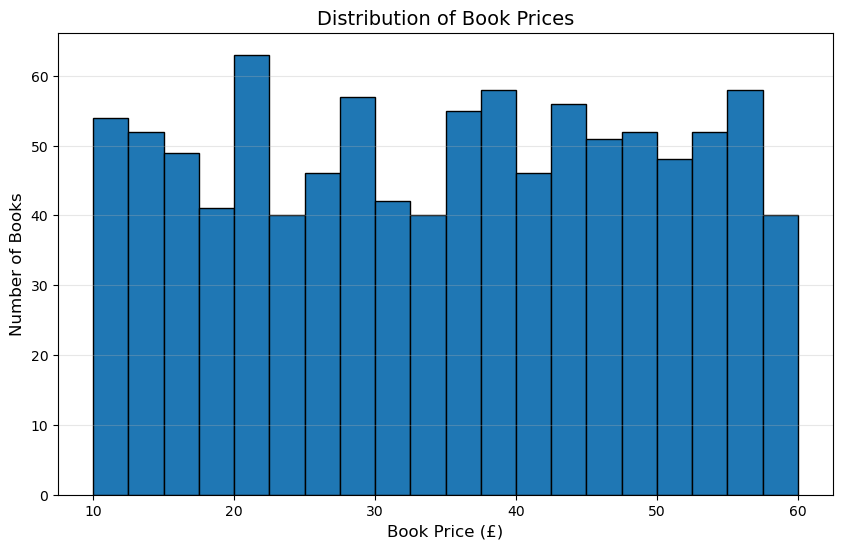

Visualization 1 saved successfully!
File: book_visualizations/01_book_price_distribution.png


In [87]:
import os
import matplotlib.pyplot as plt

# Ensure the visualization folder exists
os.makedirs("book_visualizations", exist_ok=True)

# Create the histogram
fig, ax = plt.subplots(figsize=(10, 6))

ax.hist(
    df["Price"],
    bins=20,
    edgecolor="black"
)

ax.set_title("Distribution of Book Prices", fontsize=14)
ax.set_xlabel("Book Price (£)", fontsize=12)
ax.set_ylabel("Number of Books", fontsize=12)
ax.grid(axis="y", alpha=0.3)

# Save the chart as a high-resolution PNG image
plt.savefig(
    "book_visualizations/01_book_price_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

print("Visualization 1 saved successfully!")
print("File: book_visualizations/01_book_price_distribution.png")

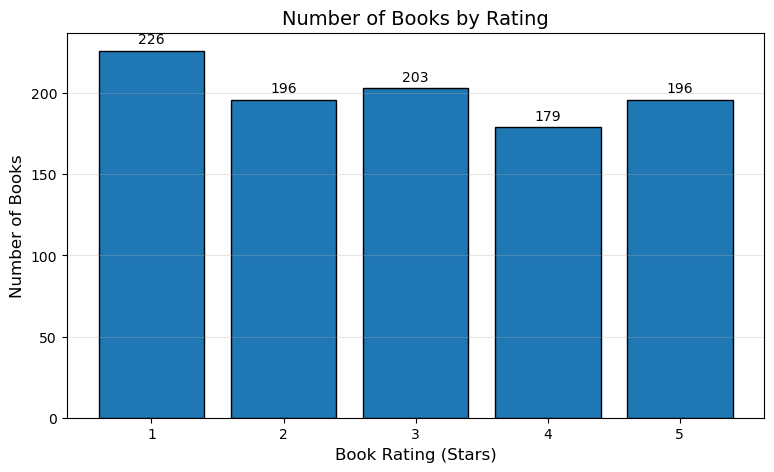

Visualization 2 saved successfully!
File: book_visualizations/02_books_by_rating.png


In [88]:
import os
import matplotlib.pyplot as plt

# Ensure the visualization folder exists
os.makedirs("book_visualizations", exist_ok=True)

# Count books in each rating category
rating_counts = (
    df["Rating_Number"]
    .value_counts()
    .sort_index()
)

# Create the bar chart
fig, ax = plt.subplots(figsize=(9, 5))

ax.bar(
    rating_counts.index,
    rating_counts.values,
    edgecolor="black"
)

ax.set_title("Number of Books by Rating", fontsize=14)
ax.set_xlabel("Book Rating (Stars)", fontsize=12)
ax.set_ylabel("Number of Books", fontsize=12)
ax.set_xticks([1, 2, 3, 4, 5])
ax.grid(axis="y", alpha=0.3)

# Add values above the bars
ax.bar_label(ax.containers[0], padding=3)

# Save the chart
plt.savefig(
    "book_visualizations/02_books_by_rating.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

print("Visualization 2 saved successfully!")
print("File: book_visualizations/02_books_by_rating.png")

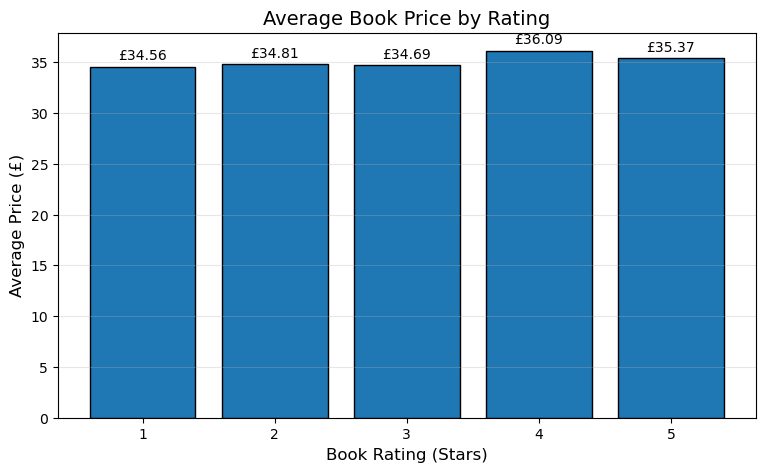

Visualization 3 saved successfully!
File: book_visualizations/03_average_price_by_rating.png


In [89]:
import os
import matplotlib.pyplot as plt

# Ensure the visualization folder exists
os.makedirs("book_visualizations", exist_ok=True)

# Calculate average price for each rating
average_price = (
    df.groupby("Rating_Number")["Price"]
    .mean()
    .sort_index()
)

# Create the bar chart
fig, ax = plt.subplots(figsize=(9, 5))

ax.bar(
    average_price.index,
    average_price.values,
    edgecolor="black"
)

ax.set_title("Average Book Price by Rating", fontsize=14)
ax.set_xlabel("Book Rating (Stars)", fontsize=12)
ax.set_ylabel("Average Price (£)", fontsize=12)
ax.set_xticks([1, 2, 3, 4, 5])
ax.grid(axis="y", alpha=0.3)

# Display average prices above the bars
ax.bar_label(
    ax.containers[0],
    labels=[f"£{value:.2f}" for value in average_price.values],
    padding=3
)

# Save the chart
plt.savefig(
    "book_visualizations/03_average_price_by_rating.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

print("Visualization 3 saved successfully!")
print("File: book_visualizations/03_average_price_by_rating.png")

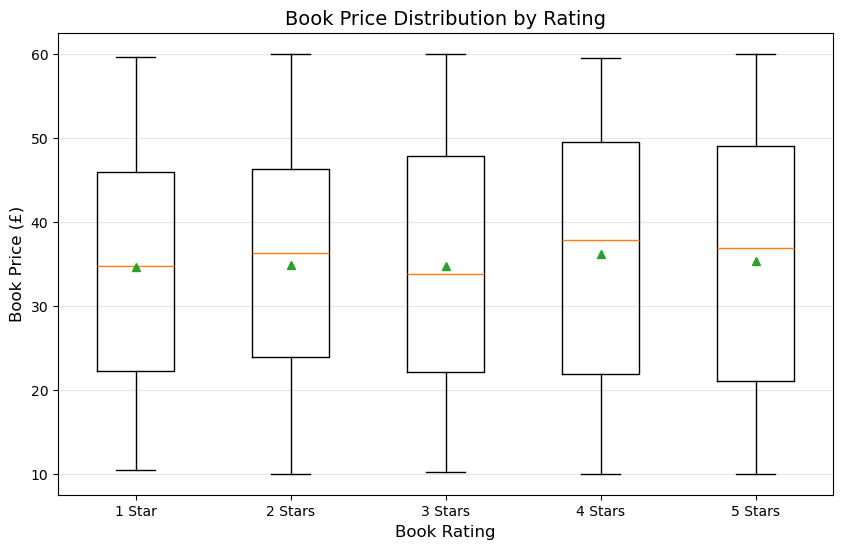

Visualization 4 saved successfully!
File: book_visualizations/04_price_distribution_by_rating.png


In [90]:
import os
import matplotlib.pyplot as plt

# Ensure the visualization folder exists
os.makedirs("book_visualizations", exist_ok=True)

# Prepare prices for each rating category
ratings = sorted(df["Rating_Number"].dropna().unique())

price_data = [
    df.loc[df["Rating_Number"] == rating, "Price"].dropna()
    for rating in ratings
]

# Create the box plot
fig, ax = plt.subplots(figsize=(10, 6))

ax.boxplot(
    price_data,
    tick_labels=[f"{rating} Star" if rating == 1
                 else f"{rating} Stars" for rating in ratings],
    showmeans=True
)

ax.set_title("Book Price Distribution by Rating", fontsize=14)
ax.set_xlabel("Book Rating", fontsize=12)
ax.set_ylabel("Book Price (£)", fontsize=12)
ax.grid(axis="y", alpha=0.3)

# Save the chart
plt.savefig(
    "book_visualizations/04_price_distribution_by_rating.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

print("Visualization 4 saved successfully!")
print("File: book_visualizations/04_price_distribution_by_rating.png")

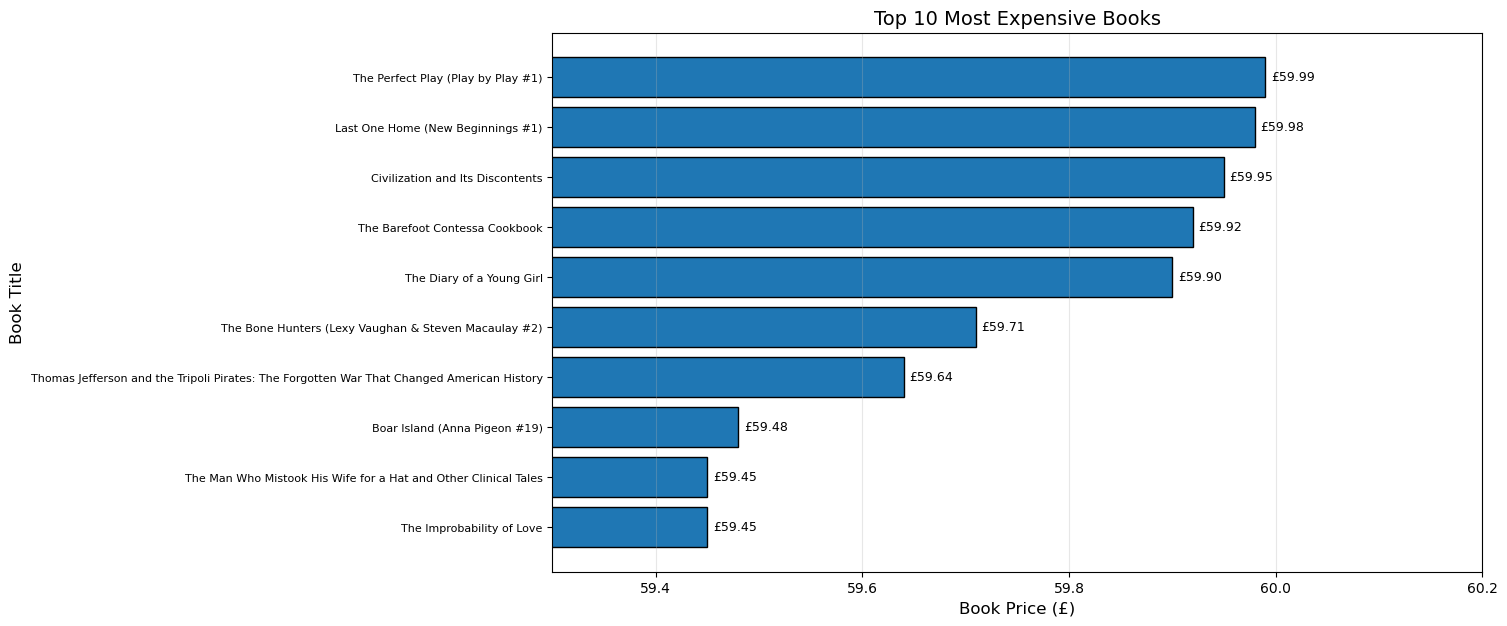

Visualization 5 saved successfully!
File: book_visualizations/05_top_10_most_expensive.png


In [91]:
import os
import matplotlib.pyplot as plt

# Ensure the visualization folder exists
os.makedirs("book_visualizations", exist_ok=True)

# Select the 10 most expensive books
top_10_expensive = (
    df.nlargest(10, "Price")
    .sort_values("Price", ascending=True)
)

# Create the horizontal bar chart
fig, ax = plt.subplots(figsize=(12, 7))

bars = ax.barh(
    top_10_expensive["Title"],
    top_10_expensive["Price"],
    edgecolor="black"
)

ax.set_title("Top 10 Most Expensive Books", fontsize=14)
ax.set_xlabel("Book Price (£)", fontsize=12)
ax.set_ylabel("Book Title", fontsize=12)

# Zoom in to highlight differences between prices
ax.set_xlim(59.3, 60.2)

# Add price labels
ax.bar_label(
    bars,
    labels=[f"£{price:.2f}" for price in top_10_expensive["Price"]],
    padding=4,
    fontsize=9
)

ax.grid(axis="x", alpha=0.3)
ax.tick_params(axis="y", labelsize=8)

# Save the chart
plt.savefig(
    "book_visualizations/05_top_10_most_expensive.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

print("Visualization 5 saved successfully!")
print("File: book_visualizations/05_top_10_most_expensive.png")

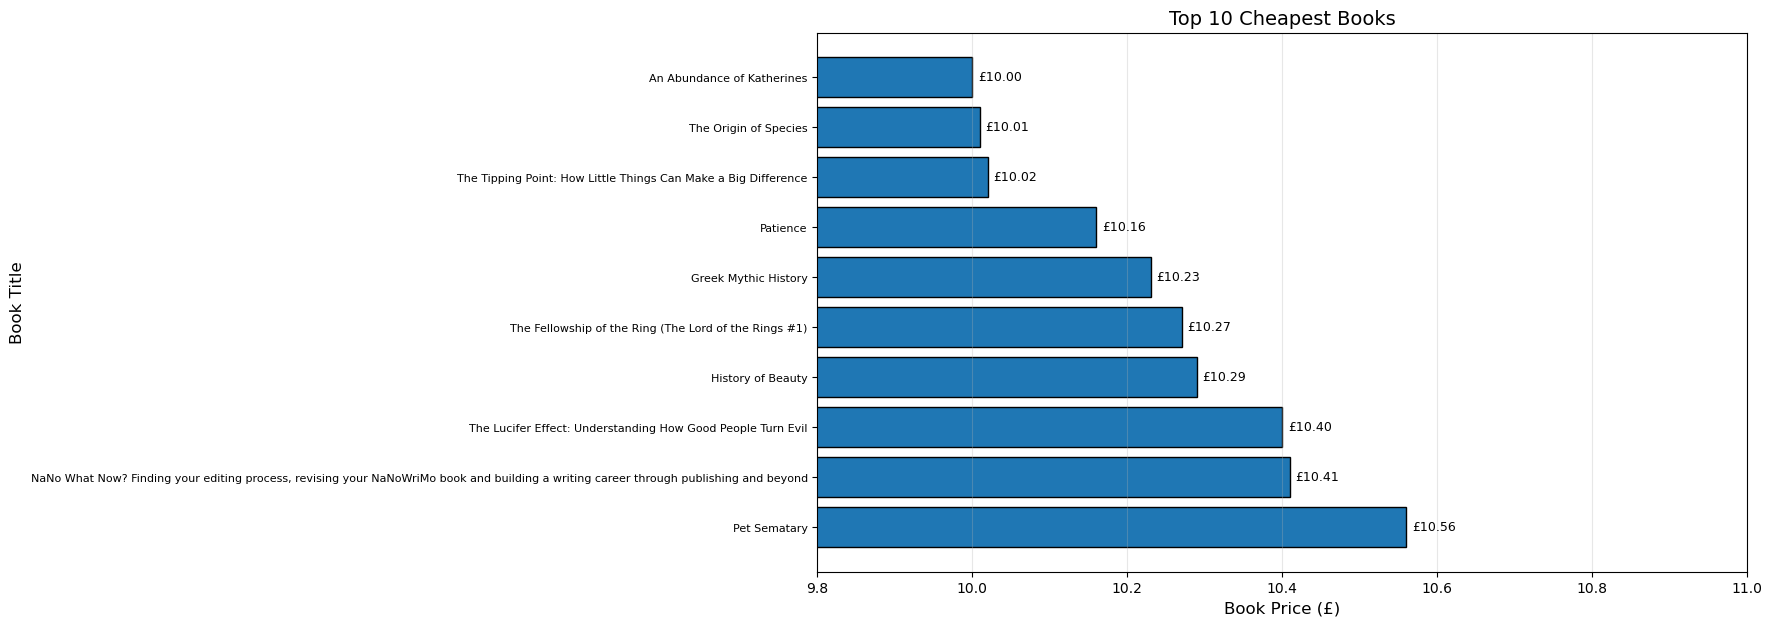

Visualization 6 saved successfully!
File: book_visualizations/06_top_10_cheapest.png


In [92]:
import os
import matplotlib.pyplot as plt

# Ensure the visualization folder exists
os.makedirs("book_visualizations", exist_ok=True)

# Select the 10 cheapest books
top_10_cheapest = (
    df.nsmallest(10, "Price")
    .sort_values("Price", ascending=False)
)

# Create the horizontal bar chart
fig, ax = plt.subplots(figsize=(12, 7))

bars = ax.barh(
    top_10_cheapest["Title"],
    top_10_cheapest["Price"],
    edgecolor="black"
)

ax.set_title("Top 10 Cheapest Books", fontsize=14)
ax.set_xlabel("Book Price (£)", fontsize=12)
ax.set_ylabel("Book Title", fontsize=12)

# Set the horizontal axis range
ax.set_xlim(9.8, 11.0)

# Add price labels to the bars
ax.bar_label(
    bars,
    labels=[f"£{price:.2f}" for price in top_10_cheapest["Price"]],
    padding=4,
    fontsize=9
)

ax.grid(axis="x", alpha=0.3)
ax.tick_params(axis="y", labelsize=8)

# Save the chart
plt.savefig(
    "book_visualizations/06_top_10_cheapest.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

print("Visualization 6 saved successfully!")
print("File: book_visualizations/06_top_10_cheapest.png")

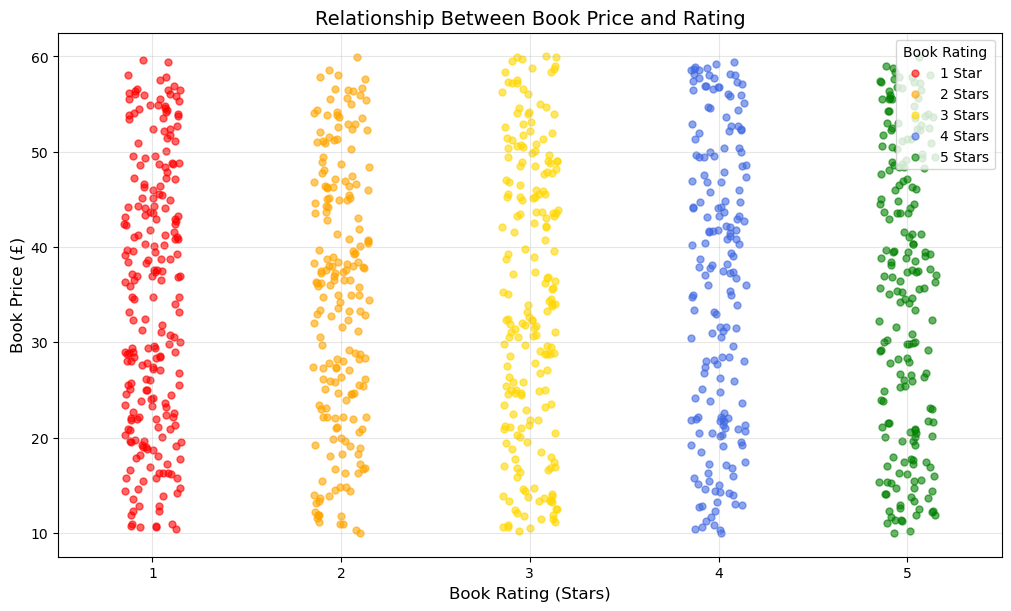

Visualization 7 saved successfully!
File: book_visualizations/07_price_vs_rating.png


In [93]:
import os
import numpy as np
import matplotlib.pyplot as plt

# Ensure the visualization folder exists
os.makedirs("book_visualizations", exist_ok=True)

# Set a random seed to make the chart reproducible
np.random.seed(42)

# Add slight horizontal jitter to separate overlapping points
rating_jitter = df["Rating_Number"] + np.random.uniform(
    -0.15, 0.15, size=len(df)
)

# Define colours for each rating
rating_colors = {
    1: "red",
    2: "orange",
    3: "gold",
    4: "royalblue",
    5: "green"
}

# Create the scatter plot
fig, ax = plt.subplots(
    figsize=(10, 6),
    constrained_layout=True
)

# Plot each rating category separately
for rating in sorted(df["Rating_Number"].dropna().unique()):
    mask = df["Rating_Number"] == rating

    ax.scatter(
        rating_jitter[mask],
        df.loc[mask, "Price"],
        color=rating_colors[rating],
        label=f"{rating} Star" if rating == 1 else f"{rating} Stars",
        alpha=0.6,
        s=25
    )

# Add chart title and axis labels
ax.set_title(
    "Relationship Between Book Price and Rating",
    fontsize=14
)
ax.set_xlabel("Book Rating (Stars)", fontsize=12)
ax.set_ylabel("Book Price (£)", fontsize=12)

# Format the rating axis
ax.set_xticks([1, 2, 3, 4, 5])
ax.set_xlim(0.5, 5.5)

# Add grid and legend
ax.grid(True, alpha=0.3)
ax.legend(title="Book Rating", loc="upper right")

# Save the chart
plt.savefig(
    "book_visualizations/07_price_vs_rating.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

print("Visualization 7 saved successfully!")
print("File: book_visualizations/07_price_vs_rating.png")

In [94]:
import os

# Define the visualization folder
visualization_folder = "book_visualizations"

# List the expected visualization files
expected_files = [
    "01_book_price_distribution.png",
    "02_books_by_rating.png",
    "03_average_price_by_rating.png",
    "04_price_distribution_by_rating.png",
    "05_top_10_most_expensive.png",
    "06_top_10_cheapest.png",
    "07_price_vs_rating.png"
]

print("VERIFICATION OF BOOK PROJECT VISUALIZATIONS")
print("-" * 50)

saved_count = 0

for filename in expected_files:
    file_path = os.path.join(visualization_folder, filename)

    if os.path.exists(file_path):
        file_size = os.path.getsize(file_path) / 1024
        print(f"SUCCESS: {filename} ({file_size:.2f} KB)")
        saved_count += 1
    else:
        print(f"MISSING: {filename}")

print("-" * 50)
print(f"Total visualizations saved: {saved_count}/7")

if saved_count == 7:
    print("SUCCESS: All seven visualizations are saved!")
else:
    print("Some files are missing. We will investigate them.")

VERIFICATION OF BOOK PROJECT VISUALIZATIONS
--------------------------------------------------
SUCCESS: 01_book_price_distribution.png (75.95 KB)
SUCCESS: 02_books_by_rating.png (81.25 KB)
SUCCESS: 03_average_price_by_rating.png (96.06 KB)
SUCCESS: 04_price_distribution_by_rating.png (80.34 KB)
SUCCESS: 05_top_10_most_expensive.png (245.49 KB)
SUCCESS: 06_top_10_cheapest.png (240.48 KB)
SUCCESS: 07_price_vs_rating.png (827.42 KB)
--------------------------------------------------
Total visualizations saved: 7/7
SUCCESS: All seven visualizations are saved!


In [95]:
import os

print("Current working directory:")
print(os.getcwd())

print("\nNotebook and project files:")
print(os.listdir())

Current working directory:
C:\Users\BRAFAZ

Notebook and project files:
['.ai-navigator', '.anaconda', '.conda', '.continuum', '.idlerc', '.ipynb_checkpoints', '.ipython', '.jupyter', '.mamba', '.matplotlib', '.opera', '.python_history', '.virtual_documents', '20CDAAN.ipynb', '20CDAAN_first_class.ipynb', '3D Objects', 'anaconda3', 'anaconda_projects', 'AppData', 'Apple', 'Application Data', 'books_dataset_cleaned.csv', 'Books_web_scrapping_project1.ipynb', 'book_visualizations', 'Book_Web_Scrapping_Project.ipynb', 'Contacts', 'Cookies', 'Da20c.ipynb', 'Documents', 'Downloads', 'edb_languagepack_4.exe', 'edb_languagepack_4.exe-20251218223325', 'edb_npgsql.exe', 'edb_pgagent_pg16.exe', 'edb_pgbouncer.exe', 'edb_pgjdbc.exe', 'edb_psqlodbc.exe', 'edb_psqlodbc.exe-20251215163520', 'edb_psqlodbc.exe-20251215163538', 'edb_psqlodbc.exe-20251215163549', 'edb_psqlodbc.exe-20251218223922', 'Favorites', 'IntelGraphicsProfiles', 'Links', 'Local Settings', 'Microsoft', 'Music', 'My Documents', 'NetH

In [96]:
import os

print("Current working directory:")
print(os.getcwd())

print("\nNotebook and project files:")
print(os.listdir())

Current working directory:
C:\Users\BRAFAZ

Notebook and project files:
['.ai-navigator', '.anaconda', '.conda', '.continuum', '.idlerc', '.ipynb_checkpoints', '.ipython', '.jupyter', '.mamba', '.matplotlib', '.opera', '.python_history', '.virtual_documents', '20CDAAN.ipynb', '20CDAAN_first_class.ipynb', '3D Objects', 'anaconda3', 'anaconda_projects', 'AppData', 'Apple', 'Application Data', 'books_dataset_cleaned.csv', 'Books_web_scrapping_project1.ipynb', 'book_visualizations', 'Book_Web_Scrapping_Project.ipynb', 'Contacts', 'Cookies', 'Da20c.ipynb', 'Documents', 'Downloads', 'edb_languagepack_4.exe', 'edb_languagepack_4.exe-20251218223325', 'edb_npgsql.exe', 'edb_pgagent_pg16.exe', 'edb_pgbouncer.exe', 'edb_pgjdbc.exe', 'edb_psqlodbc.exe', 'edb_psqlodbc.exe-20251215163520', 'edb_psqlodbc.exe-20251215163538', 'edb_psqlodbc.exe-20251215163549', 'edb_psqlodbc.exe-20251218223922', 'Favorites', 'IntelGraphicsProfiles', 'Links', 'Local Settings', 'Microsoft', 'Music', 'My Documents', 'NetH

In [101]:
import os 
import shutil 

# Set the base directory 
base_path = os.getcwd() 

# Create the project folder 
project_folder = os.path.join( 
    base_path, 
    "Book-Web-Scraping-Analysis" 
) 
os.makedirs(project_folder, exist_ok=True) 

# List the project files and folders to copy 
items_to_copy = [ 
    "Books_web_scrapping_project1.ipynb", 
    "books_dataset_cleaned.csv", 
    "book_visualizations" 
]

# Copy the files and folders 
for item in items_to_copy: 
    source = os.path.join(base_path, item) 
    destination = os.path.join(project_folder, item) 
    
    if not os.path.exists(source): 
        print(f"WARNING: Not found: {item}") 
        continue 
        
        if os.path.isdir(source): 
            shutil.copytree( 
                source, 
                destination, 
                dirs_exist_ok=True 
            ) 
            print(f"Folder copied: {item}") 
        else: 
            shutil.copy2(source, destination) 
            print(f"File copied: {item}") 
            
            # Verify the project folder 
            print("\nProject folder location:") 
            print(project_folder) 
            
            print("\nProject folder contents:") 
            print(os.listdir(project_folder))

In [102]:
print("Jupyter Notebook is working correctly!")

import os

print("Current folder:", os.getcwd())

Jupyter Notebook is working correctly!
Current folder: C:\Users\BRAFAZ


In [103]:
import os 

project_folder = os.path.join( 
    os.getcwd(), 
    "Book-Web-Scraping-Analysis" 
) 

os.makedirs(project_folder, exist_ok=True) 

print("Project folder created successfully!") 
print("Location:", project_folder)

Project folder created successfully!
Location: C:\Users\BRAFAZ\Book-Web-Scraping-Analysis


In [ ]:
import os 
import shutil 

base_path = os.getcwd() 
project_folder = os.path.join(base_path, "Book-Web-Scraping-Analysis") 

# Copy the notebook 
shutil.copy2(
    os.path.join(base_path, "Books_web_scrapping_project1.ipynb"), 
    os.path.join(project_folder, "Books_web_scrapping_project1.ipynb") 
) 

print("Notebook copied successfully!")

# Copy the cleaned dataset 
shutil.copy2(
    os.path.join(base_path, "books_dataset_cleaned.csv"), 
    os.path.join(project_folder, "books_dataset_cleaned.csv") 
)

print("Dataset copied successfully!") 

# Copy the visualization folder 
shutil.copytree( 
    os.path.join(base_path, "book_visualizations"), 
    os.path.join(project_folder, "book_visualizations"), 
    dirs_exist_ok=True 
)

print("Visualizations copied successfully!") 

# Display project contents 
print("\nFiles in your project folder:") 
print(os.listdir(project_folder))